# Senate Stage 1: fundamentals regression, expanding window 2012–2022

A first fundamentals-only model of the Democratic two-party Senate margin (`adj_margin_2p_norm`), in the same
backtest style as the House Stage 1 notebooks. Each eval year is fitted on **earlier elections only** and scored
out of sample:

| eval year | train years |
|---|---|
| 2012 | 2006–2010 |
| 2014 | 2006–2012 |
| … | … |
| 2022 | 2006–2020 |

2024 is held out, as in the House work: no window trains on it or scores it.

- **Rows:** one per race, keyed `year, state, class`, so a state-year with a regular race and a special is two rows.
- **Scored and trained on:** observed D-vs-R targets (`dr`, `dr_jungle`, `dr_multi`, `dr_rcv`, not imputed).
  Imputed uncontested and third-party races are left out (an ablation adds them to training).
- **Dropped (`sr.EXCLUDED_RACES`):** AK 2022, Murkowski vs Tshibaka, both Republicans. Its D-vs-R margin (−78.5)
  isn't comparable, so it is neither trained on nor scored.
- **Excluded by design:** race-level polls and Cook/Sabato/Inside Elections ratings. They are post–Stage 1 inputs.
- **Code:** `src/senate/regression/`. `backtest` fits `smf.wls` (OLS when every weight is 1) and `metrics.compare`
  scores the predictions. Nothing here is shared with the House code.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# The repository root is the first folder up from here that holds pyproject.toml, so this works at any depth
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
import senate.regression as sr  # names in src/senate/regression/__init__.py

pd.set_option("display.width", 200)

## 1. Inventory

`load_data()` joins `data/processed/senate/modeling.csv` (every race 2006–2026) to `targets.csv` (2006–2024), with
`special` from `senate_incumbency.csv`. The fundamentals available:

| Variable | Meaning |
|---|---|
| `partisan_lean` | 2 × state PVI (the two presidential elections before the year), D-positive |
| `gen_margin_raw` | election-eve generic-ballot polling margin, raw (D − R) |
| `gb_margin_2p_norm`, `gb_margin_30d_ewma_raw`, `gb_momentum_30d_raw` | other generic-ballot forms |
| `inc_signed` | +1 D incumbent, −1 R, 0 open (appointees open; King and Sanders +1) |
| `special` | 1 for a special election |
| `fundraising_advantage`, `spending_advantage` | log D/R receipts and disbursements, capped ±5 |
| ACS, CPI/gas, unemployment | state demographics and economy |

In [2]:
data = sr.load_data()
sr.inventory(data).T

year,2006,2008,2010,2012,2014,2016,2018,2020,2022,2024,2026
races,33,35,37,33,36,34,35,35,35,34,35
observed,31,34,34,33,34,32,34,34,33,33,0
excluded,0,0,0,0,0,0,0,0,1,0,0
imputed,0,1,3,0,2,2,1,1,1,1,0
no_target,2,0,0,0,0,0,0,0,0,0,35
specials,0,2,3,0,3,0,2,2,1,1,2


## 2. Settings and specifications

- **Weightings:** OLS; equal-year WLS (each training year carries the same total weight, whatever its number of
  races); equal-year WLS with a 6-year recency half-life.
- **Competitive subsets (House definitions):** ex ante `|partisan_lean + gb_margin_2p_norm| <= 10`, the
  uniform-swing expectation known before the election; ex post `|actual| <= 7.5`. Senate subsets are small (about
  10 races a year ex ante), so results are pooled over 2012–2022, and per-year numbers are noisy.
- **Fixed coefficients:** `lean_fixed_1` fixes lean at 1 (uniform swing) and estimates incumbency.
- **Fixed incumbency:** `inc_fixed_*` imposes the incumbency coefficient (points of margin per unit of `inc_signed`)
  instead of estimating it. 2.5 is the House Stage 1 value, chosen before this experiment. 5 is a sensitivity check.
  Picking the value by these backtest scores would overfit the eval years.

In [3]:
TARGET = sr.TARGET
EVAL_YEARS = [2012, 2014, 2016, 2018, 2020, 2022]  # 2024 held out
EX_ANTE_THRESHOLD = 10.0  # points, as in the House
EX_POST_THRESHOLD = 7.5
FIXED_INC = 2.5           # House Stage 1's imposed incumbency coefficient
FIXED_INC_HIGH = 5.0      # sensitivity

CLASSIC = f"{TARGET} ~ partisan_lean + gen_margin_raw + inc_signed"
NO_INC = f"{TARGET} ~ partisan_lean + gen_margin_raw"
SPECS = {  # name: (formula, fixed coefficients)
    "lean_only": (f"{TARGET} ~ partisan_lean", None),
    "lean_gb": (NO_INC, None),
    "classic": (CLASSIC, None),
    "classic_lean_x_inc": (CLASSIC + " + partisan_lean:inc_signed", None),
    "classic_special": (CLASSIC + " + special", None),
    "classic_gb_ewma": (CLASSIC.replace("gen_margin_raw", "gb_margin_30d_ewma_raw"), None),
    "classic_fundraising": (CLASSIC + " + fundraising_advantage", None),
    f"inc_fixed_{FIXED_INC:g}": (NO_INC, {"inc_signed": FIXED_INC}),
    f"inc_fixed_{FIXED_INC_HIGH:g}": (NO_INC, {"inc_signed": FIXED_INC_HIGH}),
    f"inc_fixed_{FIXED_INC:g}_special": (NO_INC + " + special", {"inc_signed": FIXED_INC}),
    # uniform-swing structure: lean's coefficient fixed at 1, incumbency estimated
    "lean_fixed_1": (f"{TARGET} ~ gen_margin_raw + inc_signed", {"partisan_lean": 1.0}),
}
WEIGHTINGS = {  # name: (equal_year, half_life)
    "ols": (False, None),
    "wls_ey": (True, None),
    "wls_ey_h6": (True, 6),
}
for name, (formula, fixed) in SPECS.items():
    print(f"{name:24s} {formula}" + (f"   fixed {fixed}" if fixed else ""))

lean_only                adj_margin_2p_norm ~ partisan_lean
lean_gb                  adj_margin_2p_norm ~ partisan_lean + gen_margin_raw
classic                  adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed
classic_lean_x_inc       adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed + partisan_lean:inc_signed
classic_special          adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed + special
classic_gb_ewma          adj_margin_2p_norm ~ partisan_lean + gb_margin_30d_ewma_raw + inc_signed
classic_fundraising      adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + inc_signed + fundraising_advantage
inc_fixed_2.5            adj_margin_2p_norm ~ partisan_lean + gen_margin_raw   fixed {'inc_signed': 2.5}
inc_fixed_5              adj_margin_2p_norm ~ partisan_lean + gen_margin_raw   fixed {'inc_signed': 5.0}
inc_fixed_2.5_special    adj_margin_2p_norm ~ partisan_lean + gen_margin_raw + special   fixed {'inc_signed': 2.5}
lean_fixed_1       

In [4]:
runs = {"uniform_swing": sr.baseline(data, expression="partisan_lean + gb_margin_2p_norm", eval_years=EVAL_YEARS,
                                     name="uniform_swing")}  # no fitted parameters: the ex-ante expectation
for spec, (formula, fixed) in SPECS.items():
    for weighting, (equal_year, half_life) in WEIGHTINGS.items():
        name = f"{spec}|{weighting}"
        runs[name] = sr.backtest(data, formula=formula, eval_years=EVAL_YEARS, name=name, equal_year=equal_year,
                                 half_life=half_life, fixed=fixed)
# every run scores the same races
assert len({tuple(map(tuple, run.predictions[["year", "state", "class"]].values)) for run in runs.values()}) == 1
print(len(runs), "runs;", "training rows per window:", runs["classic|ols"].n_train)

34 runs; training rows per window: {2012: 99, 2014: 132, 2016: 166, 2018: 198, 2020: 232, 2022: 266}


## 3. Out-of-sample comparison

Pooled over the six eval years. Columns: `mae`, `rmse`, `bias` (mean of actual − predicted; + means Democrats
outperformed the model) and `accuracy_pct` (winner called correctly), for all scored races and each competitive
subset. Each table is ranked by overall MAE.

In [5]:
SHOW = {"all": ["n", "mae", "rmse", "bias", "accuracy_pct"], "ex_ante": ["n", "mae", "bias", "accuracy_pct"],
        "ex_post": ["n", "mae", "bias", "accuracy_pct"]}
COLUMNS = [(subset, metric) for subset, metrics in SHOW.items() for metric in metrics]


def table(names, by_year=False):
    scores = sr.compare([runs[n] for n in names], by_year=by_year, ex_ante=EX_ANTE_THRESHOLD,
                        ex_post=EX_POST_THRESHOLD)
    return scores[COLUMNS]


for weighting in WEIGHTINGS:
    names = ["uniform_swing", *(f"{spec}|{weighting}" for spec in SPECS)]
    display(Markdown(f"### `{weighting}`"))
    display(table(names).sort_values(("all", "mae")).round(2))

### `ols`

all                                 ex_ante                          ex_post                         
                               n   mae   rmse  bias accuracy_pct       n   mae  bias accuracy_pct       n   mae  bias accuracy_pct
model                                                                                                                             
inc_fixed_5|ols            200.0  6.87   9.64 -0.63         91.5    61.0  6.05 -0.96        80.33    46.0  5.36  0.89        73.91
inc_fixed_2.5|ols          200.0  7.22  10.28 -0.45         90.0    61.0  6.56 -0.77        75.41    46.0  5.69  1.39        71.74
inc_fixed_2.5_special|ols  200.0  7.26  10.33 -0.42         89.5    61.0  6.58 -0.72        73.77    46.0  5.72  1.47        69.57
classic_fundraising|ols    200.0  7.47   9.40 -3.21         90.5    61.0  5.88 -3.07        85.25    46.0  5.62 -2.76        71.74
uniform_swing              200.0  7.89  11.07  1.29         88.5    61.0  7.76  1.05        70.49    46.0  6.73  3.14        65.22
lean_gb|ols                200.0  7.93  11.20 -0.27         88.0    61.0  7.55 -0.58        68.85    46.0  6.46  1.88        67.39
lean_fixed_1|ols           200.0  8.21  10.10 -0.87         91.5    61.0  7.63 -2.15        85.25    46.0  8.03 -0.20        69.57
classic|ols                200.0  8.34  10.13 -1.43         91.0    61.0  8.36 -1.82        86.89    46.0  8.81 -1.10        71.74
classic_special|ols        200.0  8.35  10.16 -1.40         90.5    61.0  8.28 -1.77        85.25    46.0  8.79 -1.03        69.57
classic_lean_x_inc|ols     200.0  8.39  10.19 -1.44         91.5    61.0  8.40 -1.87        86.89    46.0  8.88 -1.17        71.74
classic_gb_ewma|ols        200.0  8.43  10.26 -1.09         90.5    61.0  8.42 -1.47        85.25    46.0  8.97 -0.71        69.57
lean_only|ols              200.0  8.53  11.85 -1.03         88.5    61.0  7.70 -1.39        70.49    46.0  6.53  1.65        67.39

### `wls_ey`

all                                 ex_ante                          ex_post                         
                                  n   mae   rmse  bias accuracy_pct       n   mae  bias accuracy_pct       n   mae  bias accuracy_pct
model                                                                                                                                
inc_fixed_5|wls_ey            200.0  6.88   9.65 -0.60         91.5    61.0  6.04 -0.91        80.33    46.0  5.34  0.93        73.91
inc_fixed_2.5|wls_ey          200.0  7.24  10.30 -0.42         90.0    61.0  6.56 -0.72        75.41    46.0  5.67  1.43        71.74
inc_fixed_2.5_special|wls_ey  200.0  7.27  10.35 -0.39         89.5    61.0  6.57 -0.67        73.77    46.0  5.69  1.50        69.57
classic_fundraising|wls_ey    200.0  7.51   9.44 -3.24         90.5    61.0  5.90 -3.09        85.25    46.0  5.67 -2.81        71.74
uniform_swing                 200.0  7.89  11.07  1.29         88.5    61.0  7.76  1.05        70.49    46.0  6.73  3.14        65.22
lean_gb|wls_ey                200.0  7.95  11.23 -0.23         88.0    61.0  7.55 -0.53        68.85    46.0  6.43  1.93        67.39
lean_fixed_1|wls_ey           200.0  8.24  10.12 -0.83         92.0    61.0  7.67 -2.12        85.25    46.0  8.07 -0.16        71.74
classic|wls_ey                200.0  8.39  10.18 -1.42         91.0    61.0  8.41 -1.80        86.89    46.0  8.88 -1.10        71.74
classic_special|wls_ey        200.0  8.39  10.21 -1.39         90.5    61.0  8.33 -1.75        85.25    46.0  8.86 -1.04        69.57
classic_lean_x_inc|wls_ey     200.0  8.43  10.24 -1.42         91.5    61.0  8.46 -1.87        86.89    46.0  8.95 -1.22        71.74
classic_gb_ewma|wls_ey        200.0  8.48  10.31 -1.09         90.5    61.0  8.49 -1.45        85.25    46.0  9.05 -0.72        69.57
lean_only|wls_ey              200.0  8.55  11.87 -1.11         88.5    61.0  7.70 -1.47        70.49    46.0  6.51  1.57        67.39

### `wls_ey_h6`

all                                 ex_ante                          ex_post                         
                                     n   mae   rmse  bias accuracy_pct       n   mae  bias accuracy_pct       n   mae  bias accuracy_pct
model                                                                                                                                   
inc_fixed_5|wls_ey_h6            200.0  6.91   9.65 -0.51         91.0    61.0  6.18 -0.94        78.69    46.0  5.58  1.08        71.74
classic_fundraising|wls_ey_h6    200.0  7.04   8.95 -2.67         92.5    61.0  5.67 -2.60        85.25    46.0  5.25 -2.09        71.74
inc_fixed_2.5|wls_ey_h6          200.0  7.26  10.32 -0.35         90.0    61.0  6.71 -0.79        75.41    46.0  6.02  1.57        71.74
inc_fixed_2.5_special|wls_ey_h6  200.0  7.34  10.40 -0.31         89.5    61.0  6.72 -0.70        73.77    46.0  6.05  1.69        69.57
lean_fixed_1|wls_ey_h6           200.0  7.83   9.77 -0.75         93.0    61.0  7.28 -1.96        85.25    46.0  7.64  0.03        76.09
uniform_swing                    200.0  7.89  11.07  1.29         88.5    61.0  7.76  1.05        70.49    46.0  6.73  3.14        65.22
classic|wls_ey_h6                200.0  7.94   9.73 -1.20         91.5    61.0  7.79 -1.68        85.25    46.0  8.16 -0.70        69.57
classic_special|wls_ey_h6        200.0  7.96   9.80 -1.16         91.5    61.0  7.72 -1.57        85.25    46.0  8.14 -0.58        69.57
classic_lean_x_inc|wls_ey_h6     200.0  7.99   9.81 -1.22         91.0    61.0  7.82 -1.58        85.25    46.0  8.26 -0.57        69.57
lean_gb|wls_ey_h6                200.0  7.99  11.28 -0.19         86.5    61.0  7.76 -0.63        63.93    46.0  6.90  2.06        60.87
classic_gb_ewma|wls_ey_h6        200.0  8.03   9.89 -0.91         91.0    61.0  7.85 -1.38        83.61    46.0  8.29 -0.36        67.39
lean_only|wls_ey_h6              200.0  8.58  11.93 -0.28         89.0    61.0  7.82 -0.73        72.13    46.0  6.91  2.52        69.57

### Weighting, side by side

MAE by weighting for each specification (all races, ex ante, ex post).

In [6]:
mae = table([n for n in runs if n != "uniform_swing"]).xs("mae", axis=1, level=1)
mae.index = pd.MultiIndex.from_tuples([n.split("|") for n in mae.index], names=["spec", "weighting"])
mae.unstack("weighting").round(2)

all                  ex_ante                  ex_post                 
weighting               ols wls_ey wls_ey_h6     ols wls_ey wls_ey_h6     ols wls_ey wls_ey_h6
spec                                                                                          
classic                8.34   8.39      7.94    8.36   8.41      7.79    8.81   8.88      8.16
classic_fundraising    7.47   7.51      7.04    5.88   5.90      5.67    5.62   5.67      5.25
classic_gb_ewma        8.43   8.48      8.03    8.42   8.49      7.85    8.97   9.05      8.29
classic_lean_x_inc     8.39   8.43      7.99    8.40   8.46      7.82    8.88   8.95      8.26
classic_special        8.35   8.39      7.96    8.28   8.33      7.72    8.79   8.86      8.14
inc_fixed_2.5          7.22   7.24      7.26    6.56   6.56      6.71    5.69   5.67      6.02
inc_fixed_2.5_special  7.26   7.27      7.34    6.58   6.57      6.72    5.72   5.69      6.05
inc_fixed_5            6.87   6.88      6.91    6.05   6.04      6.18    5.36   5.34      5.58
lean_fixed_1           8.21   8.24      7.83    7.63   7.67      7.28    8.03   8.07      7.64
lean_gb                7.93   7.95      7.99    7.55   7.55      7.76    6.46   6.43      6.90
lean_only              8.53   8.55      8.58    7.70   7.70      7.82    6.53   6.51      6.91

### By eval year

Overall MAE for each window (equal-year WLS), with the uniform-swing baseline. A specification that wins only in
the early windows is leaning on 2006–2010 behaviour.

In [7]:
by_year = table(["uniform_swing", *(f"{spec}|wls_ey" for spec in SPECS)], by_year=True)
display(by_year[("all", "mae")].unstack("eval_year").round(2))
display(Markdown("Ex-ante competitive MAE (n per year in the second table):"))
display(by_year[("ex_ante", "mae")].unstack("eval_year").round(2))
display(by_year[("ex_ante", "n")].unstack("eval_year").iloc[[0]].astype(int))

eval_year,2012,2014,2016,2018,2020,2022
model,,,,,,
classic_fundraising|wls_ey,6.27,10.48,7.36,6.90,7.18,6.82
classic_gb_ewma|wls_ey,7.54,10.73,9.28,8.60,8.21,6.47
classic_lean_x_inc|wls_ey,7.19,10.94,9.31,8.51,8.17,6.41
classic_special|wls_ey,7.23,10.70,9.33,8.50,8.16,6.38
classic|wls_ey,7.23,10.66,9.31,8.51,8.17,6.41
inc_fixed_2.5_special|wls_ey,10.43,7.67,9.09,6.48,4.97,5.14
inc_fixed_2.5|wls_ey,10.32,7.60,9.13,6.39,4.98,5.17
inc_fixed_5|wls_ey,9.16,7.48,8.36,5.94,5.39,5.05
lean_fixed_1|wls_ey,7.68,9.12,8.19,9.39,7.90,7.11


Ex-ante competitive MAE (n per year in the second table):

eval_year,2012,2014,2016,2018,2020,2022
model,,,,,,
classic_fundraising|wls_ey,4.27,11.51,5.60,4.90,3.10,6.16
classic_gb_ewma|wls_ey,6.60,12.53,9.25,9.01,7.91,5.39
classic_lean_x_inc|wls_ey,6.61,12.66,9.26,8.93,7.78,5.30
classic_special|wls_ey,6.44,12.28,9.27,8.65,7.80,5.30
classic|wls_ey,6.52,12.47,9.24,8.92,7.79,5.31
inc_fixed_2.5_special|wls_ey,8.86,9.01,8.19,4.62,3.10,4.74
inc_fixed_2.5|wls_ey,8.69,9.01,8.27,4.66,3.13,4.67
inc_fixed_5|wls_ey,7.60,9.24,6.83,4.60,3.27,4.04
lean_fixed_1|wls_ey,7.01,12.35,7.90,7.59,6.66,4.16


eval_year,2012,2014,2016,2018,2020,2022
model,,,,,,
classic_fundraising|wls_ey,11,10,12,9,10,9


### Ablation: training on imputed targets

The default trains on observed D-vs-R races only. Adding the 12 imputed targets (uncontested and
third-party-runner-up races) gives the model more rows. But those targets are themselves model-based.

In [8]:
imputed_runs = [
    sr.backtest(data, formula=CLASSIC, eval_years=EVAL_YEARS, name="classic|wls_ey|train_imputed", equal_year=True,
                train_imputed=True),
    sr.backtest(data, formula=NO_INC, eval_years=EVAL_YEARS, name=f"inc_fixed_{FIXED_INC:g}|wls_ey|train_imputed",
                equal_year=True, fixed={"inc_signed": FIXED_INC}, train_imputed=True),
]
pd.concat([table(["classic|wls_ey", f"inc_fixed_{FIXED_INC:g}|wls_ey"]),
           sr.compare(imputed_runs, ex_ante=EX_ANTE_THRESHOLD, ex_post=EX_POST_THRESHOLD)[COLUMNS]]).round(2)

all                                 ex_ante                          ex_post                         
                                        n   mae   rmse  bias accuracy_pct       n   mae  bias accuracy_pct       n   mae  bias accuracy_pct
model                                                                                                                                      
classic|wls_ey                      200.0  8.39  10.18 -1.42         91.0    61.0  8.41 -1.80        86.89    46.0  8.88 -1.10        71.74
inc_fixed_2.5|wls_ey                200.0  7.24  10.30 -0.42         90.0    61.0  6.56 -0.72        75.41    46.0  5.67  1.43        71.74
classic|wls_ey|train_imputed        200.0  8.31  10.14 -1.47         91.0    61.0  8.33 -1.81        86.89    46.0  8.76 -1.11        71.74
inc_fixed_2.5|wls_ey|train_imputed  200.0  7.25  10.30 -0.37         90.0    61.0  6.56 -0.67        75.41    46.0  5.65  1.47        71.74

## 4. Coefficients

Coefficients by window (equal-year WLS), for the shortlisted specifications. A fixed term shows its imposed value.

In [9]:
SHORTLIST = ["lean_gb", "classic", "lean_fixed_1", "classic_fundraising", f"inc_fixed_{FIXED_INC:g}",
             f"inc_fixed_{FIXED_INC_HIGH:g}"]
pd.concat({spec: runs[f"{spec}|wls_ey"].coefficients for spec in SHORTLIST}, names=["spec"]).round(2)

Intercept  partisan_lean  gen_margin_raw  inc_signed  fundraising_advantage
spec                eval_year                                                                             
lean_gb             2012            1.59           0.94            0.81         NaN                    NaN
                    2014            3.47           0.99            0.76         NaN                    NaN
                    2016            2.86           1.01            0.81         NaN                    NaN
                    2018            1.94           1.05            0.83         NaN                    NaN
                    2020            2.03           1.01            0.88         NaN                    NaN
                    2022            1.84           1.02            0.85         NaN                    NaN
classic             2012            0.36           0.61            0.86       16.30                    NaN
                    2014            0.95           0.65            0.85       16.28                    NaN
                    2016           -0.12           0.70            0.94       14.71                    NaN
                    2018            0.22           0.74            0.94       14.02                    NaN
                    2020           -0.11           0.74            0.86       12.81                    NaN
                    2022           -0.08           0.76            0.84       11.74                    NaN
lean_fixed_1        2012            2.11           1.00            0.86       12.62                    NaN
                    2014            2.40           1.00            0.85       12.77                    NaN
                    2016            1.59           1.00            0.91       11.62                    NaN
                    2018            1.55           1.00            0.91       11.16                    NaN
                    2020            1.33           1.00            0.85       10.04                    NaN
                    2022            1.33           1.00            0.85        9.11                    NaN
classic_fundraising 2012            1.72           0.38            0.52        7.26                   6.05
                    2014            2.69           0.43            0.52        7.99                   5.52
                    2016            0.77           0.48            0.69        7.76                   4.99
                    2018            0.40           0.50            0.70        7.64                   4.78
                    2020            0.04           0.51            0.61        6.72                   4.72
                    2022           -0.31           0.55            0.57        6.59                   4.44
inc_fixed_2.5       2012            1.40           0.89            0.82        2.50                    NaN
                    2014            3.08           0.94            0.77        2.50                    NaN
                    2016            2.36           0.95            0.83        2.50                    NaN
                    2018            1.64           0.99            0.84        2.50                    NaN
                    2020            1.61           0.96            0.87        2.50                    NaN
                    2022            1.43           0.97            0.85        2.50                    NaN
inc_fixed_5         2012            1.21           0.84            0.83        5.00                    NaN
                    2014            2.69           0.88            0.79        5.00                    NaN
                    2016            1.85           0.90            0.85        5.00                    NaN
                    2018            1.33           0.94            0.86        5.00                    NaN
                    2020            1.20           0.91            0.87        5.00                    NaN
                    2022            1.02           0.91            0.85 

### Sensitivity to individual cycles

The 2024 window's fit (2006–2022, the training set a 2024 forecast would use; no 2024 data) is refitted with each
training year dropped in turn.

In [10]:
for spec in ["classic", f"inc_fixed_{FIXED_INC:g}"]:
    formula, fixed = SPECS[spec]
    display(Markdown(f"**{spec}** (equal-year WLS)"))
    display(sr.drop_one_cycle(data, formula=formula, eval_year=2024, equal_year=True, fixed=fixed).round(2))

**classic** (equal-year WLS)

,Intercept,partisan_lean,gen_margin_raw,inc_signed
dropped_year,,,,
none,0.28,0.77,0.82,11.14
2006,0.77,0.85,0.89,9.32
2008,0.14,0.79,0.75,10.59
2010,0.18,0.75,0.82,11.35
2012,-0.25,0.77,0.84,10.62
2014,0.86,0.75,0.75,11.57
2016,0.20,0.75,0.82,11.22
2018,0.48,0.78,0.87,11.77
2020,0.26,0.75,0.84,12.04


**inc_fixed_2.5** (equal-year WLS)

,Intercept,partisan_lean,gen_margin_raw
dropped_year,,,
none,1.69,0.97,0.83
2006,1.92,1.01,0.95
2008,1.51,0.97,0.77
2010,1.80,0.95,0.80
2012,0.88,0.95,0.85
2014,1.95,0.97,0.80
2016,2.18,0.95,0.81
2018,1.71,0.99,0.80
2020,1.85,0.96,0.86


## 5. Residual diagnostics

Residual = actual − predicted (+: Democrats outperformed the model), pooled over the eval years, for the
shortlisted specifications under equal-year WLS.

In [11]:
short_runs = [runs[f"{spec}|wls_ey"] for spec in SHORTLIST]
display(Markdown("**By eval year** (a year-wide bias is a national miss the generic ballot didn't capture)"))
display(sr.residuals_by(short_runs, "eval_year")["bias"].unstack("eval_year").round(2))
display(Markdown("**Special vs regular elections**"))
display(sr.residuals_by(short_runs, "special").unstack("special").round(2))
display(Markdown("**By incumbency** (`inc_signed`: −1 R incumbent, 0 open, +1 D incumbent)"))
display(sr.residuals_by(short_runs, "inc_signed").unstack("inc_signed").round(2))

**By eval year** (a year-wide bias is a national miss the generic ballot didn't capture)

eval_year,2012,2014,2016,2018,2020,2022
model,,,,,,
lean_gb|wls_ey,5.88,-2.60,-6.37,3.23,-3.01,1.33
classic|wls_ey,1.55,-5.64,0.91,-5.12,-1.62,1.70
lean_fixed_1|wls_ey,1.04,-3.52,-0.29,-3.50,-0.49,1.96
classic_fundraising|wls_ey,3.65,-7.94,-2.11,-5.93,-6.38,-0.41
inc_fixed_2.5|wls_ey,5.22,-3.07,-5.14,1.74,-2.73,1.41
inc_fixed_5|wls_ey,4.55,-3.54,-3.90,0.25,-2.46,1.49


**Special vs regular elections**

n     bias         mae      
special                       0  1     0     1     0     1
model                                                     
lean_gb|wls_ey              192  8 -0.22 -0.49  8.08  4.85
classic|wls_ey              192  8 -1.42 -1.59  8.40  8.18
lean_fixed_1|wls_ey         192  8 -0.86 -0.03  8.39  4.65
classic_fundraising|wls_ey  192  8 -3.33 -1.10  7.63  4.76
inc_fixed_2.5|wls_ey        192  8 -0.41 -0.73  7.32  5.32
inc_fixed_5|wls_ey          192  8 -0.59 -0.97  6.92  5.79

**By incumbency** (`inc_signed`: −1 R incumbent, 0 open, +1 D incumbent)

n          bias               mae            
inc_signed                  -1   0   1    -1     0     1    -1     0     1
model                                                                     
lean_gb|wls_ey              70  45  85 -7.32 -0.45  5.71  9.09  6.04  8.03
classic|wls_ey              70  45  85  3.02 -1.19 -5.21  8.73  7.28  8.69
lean_fixed_1|wls_ey         70  45  85  4.22 -0.18 -5.33  9.26  5.98  8.60
classic_fundraising|wls_ey  70  45  85 -0.46 -2.03 -6.18  6.79  7.04  8.36
inc_fixed_2.5|wls_ey        70  45  85 -5.48 -0.59  3.83  8.07  6.16  7.13
inc_fixed_5|wls_ey          70  45  85 -3.63 -0.72  1.95  7.52  6.29  6.66

In [12]:
RECOMMENDED = f"inc_fixed_{FIXED_INC:g}|wls_ey"
N_WORST = 12
worst = runs[RECOMMENDED].predictions.assign(abs_residual=lambda d: d["residual"].abs())
worst.nlargest(N_WORST, "abs_residual")[["year", "state", "class", "special", "inc_signed", "partisan_lean",
                                         "prediction", "actual", "residual"]].round(1)

,year,state,class,special,inc_signed,partisan_lean,prediction,actual,residual
45,2014,ME,2,0,-1,11.4,9.8,-37.0,-46.8
85,2016,ND,3,0,-1,-22.2,-19.3,-64.4,-45.1
31,2012,WV,1,0,1,-18.2,-10.3,24.8,35.1
131,2018,WV,1,0,1,-42.7,-31.1,3.5,34.5
75,2016,IA,3,0,-1,2.1,3.8,-25.5,-29.3
11,2012,MN,1,0,1,3.8,9.3,36.2,27.0
94,2016,SD,3,0,-1,-20.8,-18.0,-43.7,-25.7
20,2012,NY,1,0,1,20.1,23.8,46.6,22.8
89,2016,OH,3,0,-1,-1.4,0.5,-21.9,-22.5
153,2020,NE,2,0,-1,-28.5,-21.9,-44.0,-22.1


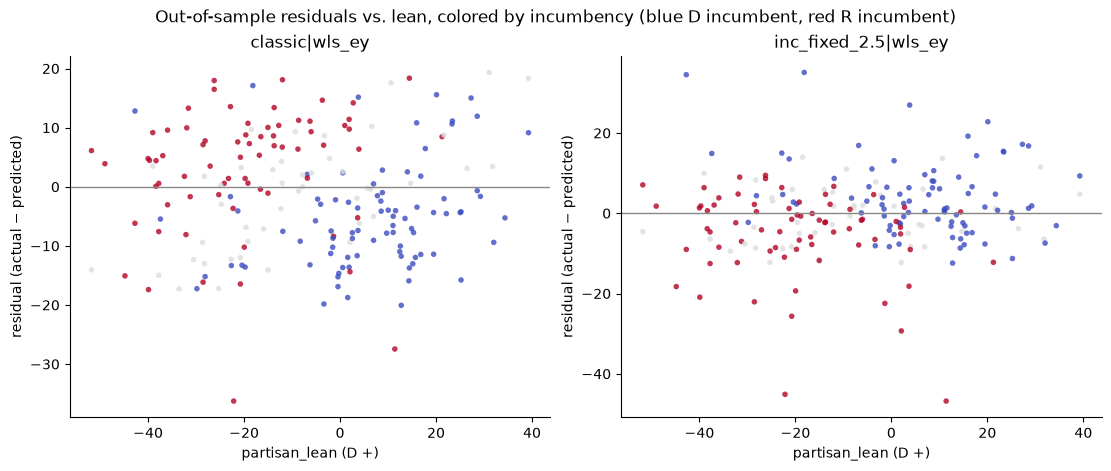

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
for ax, name in zip(axes, ["classic|wls_ey", RECOMMENDED]):
    p = runs[name].predictions
    ax.scatter(p["partisan_lean"], p["residual"], c=p["inc_signed"], cmap="coolwarm_r", vmin=-1, vmax=1, s=16,
               alpha=0.8, linewidths=0)
    ax.axhline(0, color="#888", lw=1)
    ax.set(xlabel="partisan_lean (D +)", ylabel="residual (actual − predicted)", title=name)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Out-of-sample residuals vs. lean, colored by incumbency (blue D incumbent, red R incumbent)")
plt.show()

## 6. Findings and recommendation

**Data.** Ten cycles, 2006–2024, with 332 observed D-vs-R races (12 imputed and 2 blank targets, and AK 2022,
left out). The 2012–2022 backtest scores 200 races: 61 are competitive ex ante and 46 ex post, about 10 and 8 a year. 2024 is
untouched.

**1. Estimating incumbency makes the model worse.** The fitted `classic` model (MAE 8.39) loses to uniform swing
(7.89), which has no fitted parameters, and to `lean_gb` (7.95).
- Its incumbency coefficient falls from 16.3 (2006–2010 training) to 11.7 (2006–2020). Even with lean fixed at 1
  (`lean_fixed_1`) it falls from 12.6 to 9.1.
- So the Senate incumbency advantage was large early in the sample and has shrunk, and a fit on past cycles
  overstates it in the next one. The residuals agree: `classic` over-predicts D incumbents (bias −5.2) and R
  incumbents (+3.0).
- Recency weighting (h = 6) cuts `classic` to 7.94, still no better than uniform swing.

**2. A small fixed incumbency term is the best simple fix.**

| spec (equal-year WLS) | all MAE | ex-ante MAE | ex-post MAE | bias | winners, ex ante |
|---|---|---|---|---|---|
| uniform swing | 7.89 | 7.76 | 6.73 | +1.29 | 70% |
| classic | 8.39 | 8.41 | 8.88 | −1.42 | 87% |
| `inc_fixed_2.5` | 7.24 | 6.56 | 5.67 | −0.42 | 75% |
| `inc_fixed_5` | 6.88 | 6.04 | 5.34 | −0.60 | 80% |

- 2.5 is the House's a-priori value. 5 does better here, but it was picked after seeing these scores, so it shouldn't
  be adopted from this table.
- Both still under-credit incumbents, more so R incumbents (bias −5.5 / −3.6) than D (+3.8 / +2.0). The effect is
  between 2.5 and the fitted ~10, and possibly asymmetric.
- Winner accuracy ex ante is lower for the fixed-incumbency models than for `classic` (75–80% vs 87%), although
  their margins are closer. Big incumbency terms call close-race winners well and miss margins badly.

**3. The other coefficients are stable.** With incumbency fixed:
- lean ≈ 0.89–0.99 and generic ballot ≈ 0.77–0.87 in every window;
- dropping any one cycle moves them by at most ±0.05 and ±0.13;
- the intercept is +1.4 to +3.1 (+0.6 to +1.9 with one cycle dropped), always D-leaning.

**4. Ablations that don't help** (within ±0.1 MAE): `partisan_lean:inc_signed`, `special`, the 30-day EWMA
generic ballot in place of the election-eve value, and training on imputed targets. Equal-year WLS and OLS are
nearly identical, since the years have 31–34 races each. Specials (8 scored) show no distinct bias.

**5. Fundraising** gives the best ex-ante MAE (5.90; 5.67 with recency). But:
- it over-predicts Democrats (bias −3.2);
- it shrinks lean to 0.4–0.55;
- its FEC totals run through the end of the election year, so they include post-election money and aren't a clean
  ex-ante predictor.

It's not recommended as the base.

**6. Worst misses are candidate effects that fundamentals can't see:** ME 2014 (Collins), ND 2016 (Hoeven), and WV 2012 and 2018 (Manchin). AK 2022 (Murkowski vs
Tshibaka) is dropped entirely.

**Recommendation (initial, not final):** `inc_fixed_2.5` with equal-year WLS,
`adj_margin_2p_norm ~ partisan_lean + gen_margin_raw`, with incumbency imposed at 2.5. It:
- beats uniform swing and every fitted-incumbency spec on all three subsets;
- has stable coefficients and three parameters;
- uses an incumbency value chosen before this experiment.

**Open before finalizing:**
- the incumbency value (2.5 vs ~5, and whether to split D/R), set on a principle rather than these scores;
- the 2024 holdout check, once a spec is chosen;
- fundraising, once its timing is fixed.

**Limitations:** six windows and 200 races, with competitive subsets of ~10 a year, so per-year competitive numbers
are noisy. Personal and candidate-quality effects aren't modeled. 2026 can't be backtested.